# Hoja de trabajo 2: Transformers y mecanismos de atención

+ Ana Laura Tschen 221645

In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path.cwd()
OUTPUTS = ROOT / 'outputs'
for folder in ('bert', 'gpt2', 'metrics'):
    (OUTPUTS / folder).mkdir(parents=True, exist_ok=True)
print(f'Dispositivo: {DEVICE}')

Dispositivo: cuda


In [3]:
def load_attention_model(model_name):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(
        model_name, output_attentions=True, attn_implementation='eager'
    ).to(DEVICE)
    model.eval()
    return tokenizer, model

bert_tokenizer, bert = load_attention_model('bert-base-uncased')
gpt2_tokenizer, gpt2 = load_attention_model('gpt2')
# GPT-2 no tiene token de padding, pero no lo necesita para estas inferencias.
for name, model in [('BERT', bert), ('GPT-2', gpt2)]:
    cfg = model.config
    print(f'{name}: capas={cfg.num_hidden_layers}, cabezas={cfg.num_attention_heads}, dimensión oculta={cfg.hidden_size}')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\Users\alambre1\anaconda3\envs\dm1\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alambre1\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

c:\Users\alambre1\anaconda3\envs\dm1\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alambre1\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


... (10 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

BERT: capas=12, cabezas=12, dimensión oculta=768
GPT-2: capas=12, cabezas=12, dimensión oculta=768


## Funciones generales

In [4]:
def extract_attention(model, tokenizer, text):
    encoded = tokenizer(text, return_tensors='pt', truncation=True)
    encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
    with torch.no_grad():
        result = model(**encoded)
    attentions = tuple(att.detach().cpu() for att in result.attentions)
    tokens = tokenizer.convert_ids_to_tokens(encoded['input_ids'][0].detach().cpu())
    n = len(tokens)
    expected = (1, model.config.num_attention_heads, n, n)
    assert all(tuple(layer.shape) == expected for layer in attentions), (expected, [layer.shape for layer in attentions])
    return tokens, attentions

def plot_attention_head(tokens, attentions, layer, head, title, output_path):
    """Dibuja una cabeza: filas=query y columnas=token atendido."""
    matrix = attentions[layer][0, head].numpy()
    fig, ax = plt.subplots(figsize=(max(7, len(tokens) * 0.55), max(5, len(tokens) * 0.5)))
    image = ax.imshow(matrix, cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(tokens)), tokens, rotation=65, ha='right')
    ax.set_yticks(range(len(tokens)), tokens)
    ax.set_xlabel('Token al que se presta atención')
    ax.set_ylabel('Token que consulta')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label='Peso de atención')
    fig.tight_layout()
    fig.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def attention_entropy(matrix, epsilon=1e-12):
    p = np.asarray(matrix, dtype=np.float64)
    return -np.sum(np.where(p > 0, p * np.log(p + epsilon), 0.0), axis=-1)

def mean_entropy_by_layer(attentions):
    return np.array([attention_entropy(layer.numpy()).mean() for layer in attentions])

def locate_word_tokens(tokenizer, text, word):
    encoded = tokenizer(text, return_offsets_mapping=True, add_special_tokens=True)
    start = text.lower().index(word.lower())
    end = start + len(word)
    return [i for i, (a, b) in enumerate(encoded['offset_mapping']) if b > start and a < end]

def token_index_for_word(tokenizer, text, word):
    indices = locate_word_tokens(tokenizer, text, word)
    if not indices:
        raise ValueError(f'No se encontró {word!r} en {text!r}')
    return indices[0]

## Formas de las atenciones

In [5]:
analysis_text = 'The curious animal did not cross the street because it was tired.'
bert_tokens, bert_attentions = extract_attention(bert, bert_tokenizer, analysis_text)
gpt2_tokens, gpt2_attentions = extract_attention(gpt2, gpt2_tokenizer, analysis_text)
print('BERT tokens:', bert_tokens)
print('BERT:', [tuple(x.shape) for x in bert_attentions])
print('GPT-2 tokens:', gpt2_tokens)
print('GPT-2:', [tuple(x.shape) for x in gpt2_attentions])

BERT tokens: ['[CLS]', 'the', 'curious', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'tired', '.', '[SEP]']
BERT: [(1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15)]
GPT-2 tokens: ['The', 'Ġcurious', 'Ġanimal', 'Ġdid', 'Ġnot', 'Ġcross', 'Ġthe', 'Ġstreet', 'Ġbecause', 'Ġit', 'Ġwas', 'Ġtired', '.']
GPT-2: [(1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13), (1, 12, 13, 13)]


## Visualización de cabezas de atención

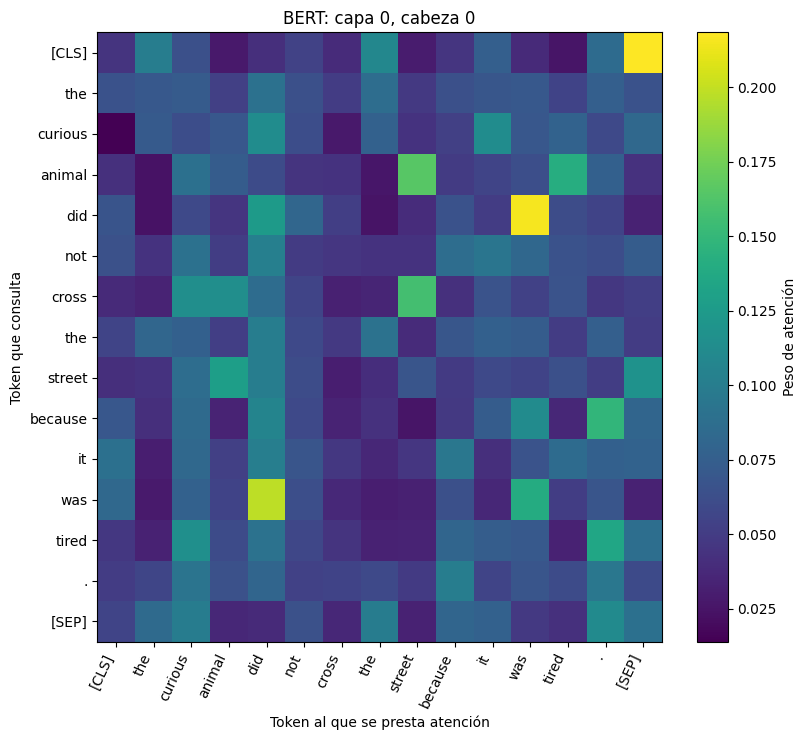

In [6]:
plot_attention_head(bert_tokens, bert_attentions, 0, 0, 'BERT: capa 0, cabeza 0', OUTPUTS / 'bert' / 'head_l0_h0.png')

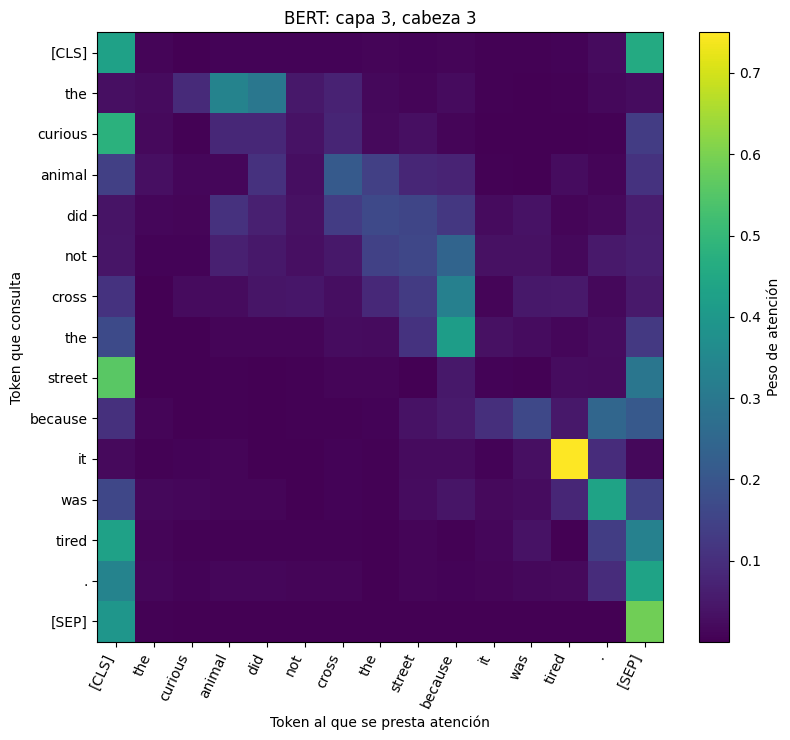

In [7]:
plot_attention_head(bert_tokens, bert_attentions, 3, 3, 'BERT: capa 3, cabeza 3', OUTPUTS / 'bert' / 'head_l3_h3.png')

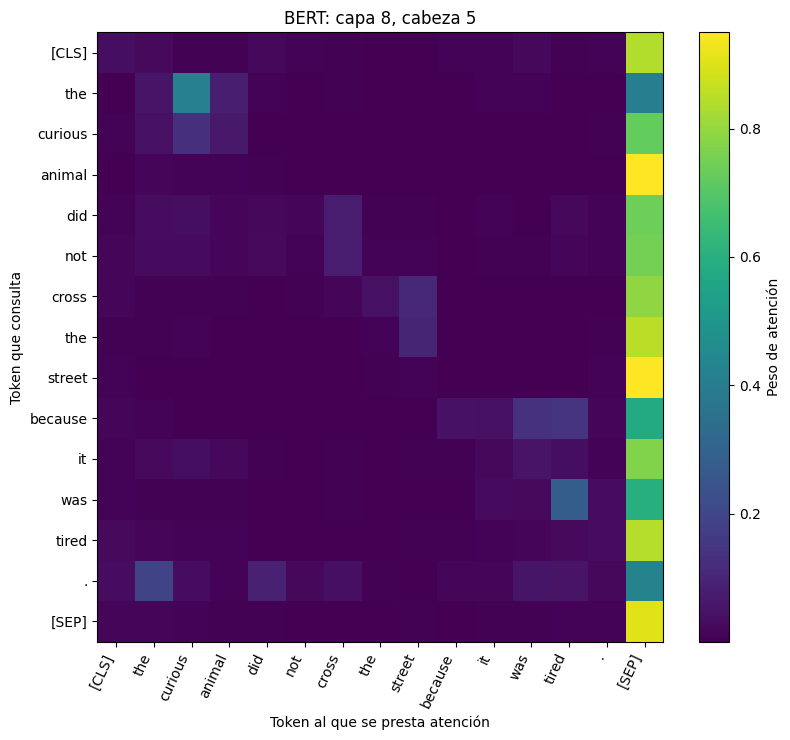

In [8]:
plot_attention_head(bert_tokens, bert_attentions, 8, 5, 'BERT: capa 8, cabeza 5', OUTPUTS / 'bert' / 'head_l8_h5.png')

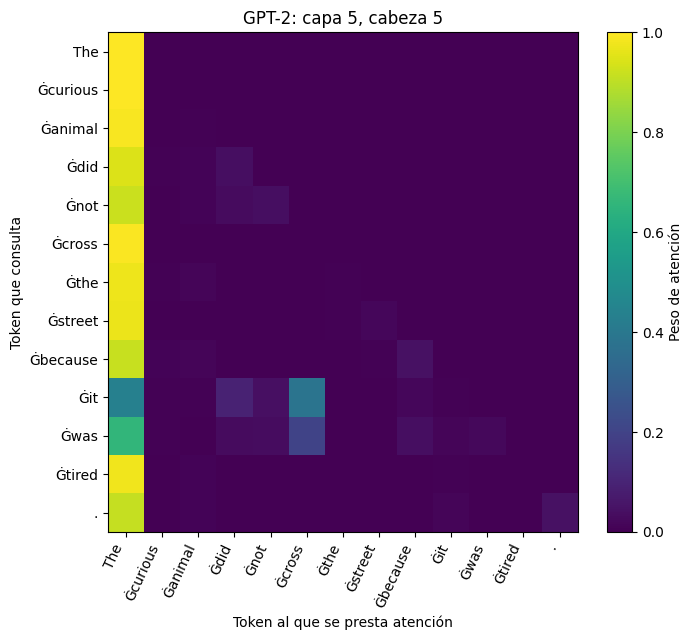

In [9]:
plot_attention_head(gpt2_tokens, gpt2_attentions, 5, 5, 'GPT-2: capa 5, cabeza 5', OUTPUTS / 'gpt2' / 'head_l5_h5.png')

## Comparación de `it` con `animal` y `street` en BERT

In [10]:
pronoun_texts = {
    'tired': 'The animal didn\'t cross the street because it was too tired.',
    'wide': 'The animal didn\'t cross the street because it was too wide.'
}
def pronoun_scores(text):
    tokens, attentions = extract_attention(bert, bert_tokenizer, text)
    indices = {word: token_index_for_word(bert_tokenizer, text, word) for word in ('it', 'animal', 'street')}
    rows = []
    for layer, tensor in enumerate(attentions):
        matrix = tensor[0].numpy()
        for head in range(matrix.shape[0]):
            rows.append({'condition': None, 'layer': layer, 'head': head,
                         'it_to_animal': matrix[head, indices['it'], indices['animal']],
                         'it_to_street': matrix[head, indices['it'], indices['street']],
                         'tokens': tokens, 'attentions': attentions})
    return indices, pd.DataFrame(rows)

all_scores = []
locations = {}
for condition, text in pronoun_texts.items():
    locations[condition], scores = pronoun_scores(text)
    scores['condition'] = condition
    all_scores.append(scores)
scores = pd.concat(all_scores, ignore_index=True)
wide_scores = scores.pivot(index=['layer', 'head'], columns='condition', values=['it_to_animal', 'it_to_street'])
wide_scores.columns = ['_'.join(c) for c in wide_scores.columns]
wide_scores = wide_scores.reset_index()
wide_scores['animal_change'] = wide_scores['it_to_animal_tired'] - wide_scores['it_to_animal_wide']
wide_scores['street_change'] = wide_scores['it_to_street_wide'] - wide_scores['it_to_street_tired']
wide_scores['pattern_score'] = wide_scores['animal_change'] + wide_scores['street_change']
print('Índices identificados:', locations)
display(wide_scores.sort_values('pattern_score', ascending=False).head(10))

Índices identificados: {'tired': {'it': 10, 'animal': 2, 'street': 8}, 'wide': {'it': 10, 'animal': 2, 'street': 8}}


,layer,head,it_to_animal_tired,it_to_animal_wide,it_to_street_tired,it_to_street_wide,animal_change,street_change,pattern_score
82,6,10,0.284269,0.011940,0.067086,0.590173,0.272329,0.523087,0.795416
106,8,10,0.675521,0.309092,0.000408,0.259248,0.366429,0.258840,0.625269
116,9,8,0.454436,0.022884,0.002548,0.044949,0.431551,0.042401,0.473952
108,9,0,0.607947,0.255371,0.002260,0.074436,0.352576,0.072175,0.424752
128,10,8,0.564286,0.244926,0.001494,0.078052,0.319360,0.076558,0.395918
100,8,4,0.241659,0.046217,0.014476,0.209082,0.195442,0.194606,0.390048
58,4,10,0.332988,0.167439,0.095223,0.288258,0.165549,0.193035,0.358584
126,10,6,0.714112,0.489658,0.008001,0.107739,0.224454,0.099738,0.324192
109,9,1,0.432198,0.341448,0.016040,0.216409,0.090750,0.200369,0.291119
103,8,7,0.205207,0.061114,0.050253,0.194367,0.144093,0.144114,0.288208


Candidato principal según el puntaje observado: {'layer': 6.0, 'head': 10.0, 'pattern_score': 0.7954158782958984}


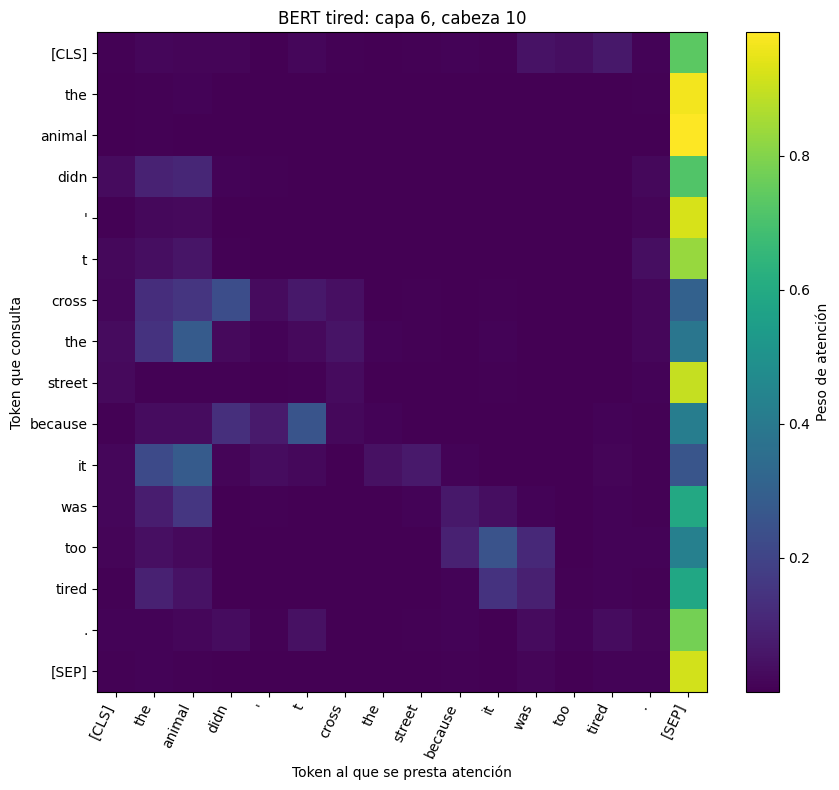

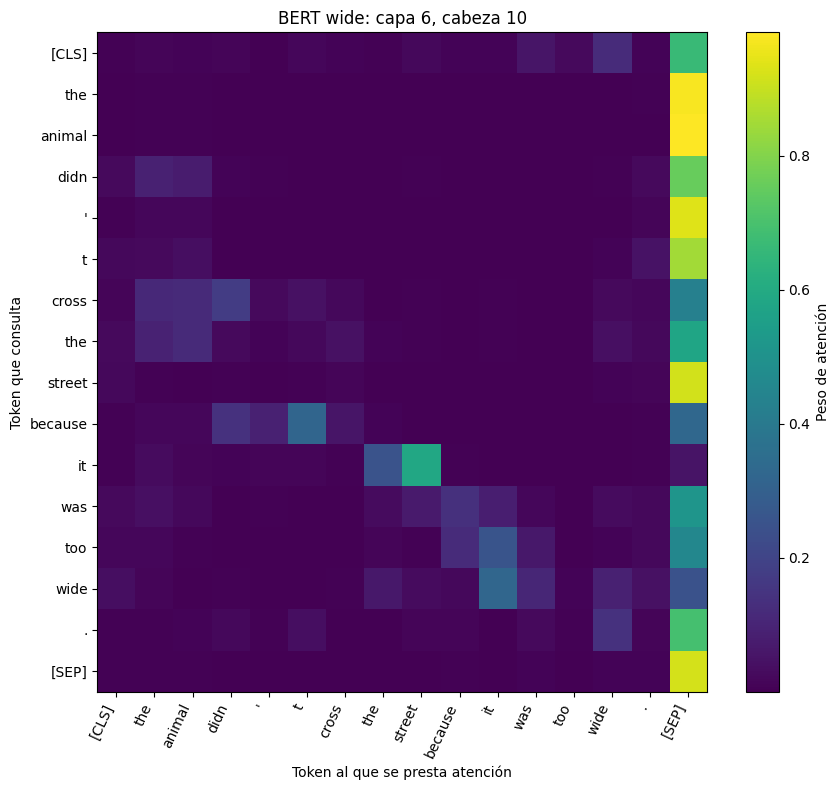

La afirmación sobre una preferencia por animal/street debe basarse en los pesos de la tabla, no solo en el nombre del candidato.


In [11]:
candidate = wide_scores.sort_values('pattern_score', ascending=False).iloc[0]
print('Candidato principal según el puntaje observado:', candidate[['layer', 'head', 'pattern_score']].to_dict())
for condition, text in pronoun_texts.items():
    tokens, attentions = extract_attention(bert, bert_tokenizer, text)
    layer, head = int(candidate['layer']), int(candidate['head'])
    plot_attention_head(tokens, attentions, layer, head, f'BERT {condition}: capa {layer}, cabeza {head}', OUTPUTS / 'bert' / f'pronoun_{condition}_l{layer}_h{head}.png')
print('La afirmación sobre una preferencia por animal/street debe basarse en los pesos de la tabla, no solo en el nombre del candidato.')

## Máscara causal y attention sinks de GPT-2

Máximo sobre la diagonal: 0.000e+00
Máscara causal verificada: True


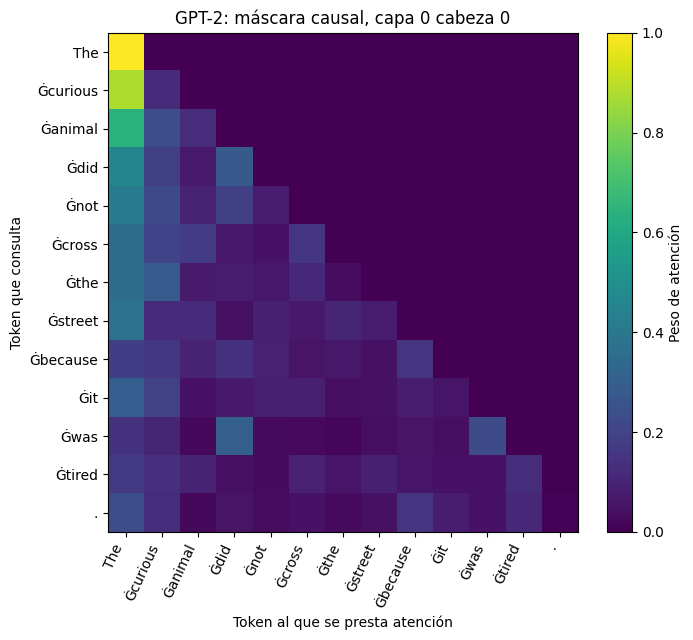

In [12]:
gpt2_upper_max = max(float(np.triu(layer[0].numpy(), k=1).max()) for layer in gpt2_attentions)
causal_verified = gpt2_upper_max <= 1e-7
print(f'Máximo sobre la diagonal: {gpt2_upper_max:.3e}')
print(f'Máscara causal verificada: {causal_verified}')
plot_attention_head(gpt2_tokens, gpt2_attentions, 0, 0, 'GPT-2: máscara causal, capa 0 cabeza 0', OUTPUTS / 'gpt2' / 'causal_mask.png')

,layer,first_token_attention
0,0,0.307114
1,1,0.485460
2,2,0.464420
3,3,0.591666
4,4,0.611898
5,5,0.743763
6,6,0.733243
7,7,0.808231
8,8,0.784104
9,9,0.847878


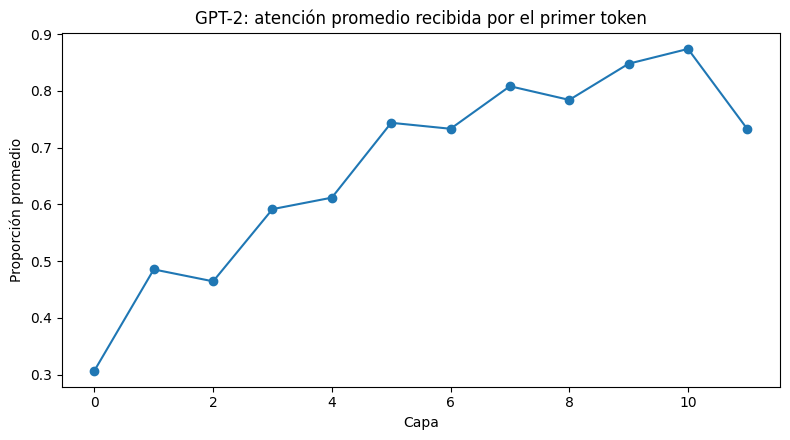

In [13]:
sink_rows = []
for layer_id, tensor in enumerate(gpt2_attentions):
    matrix = tensor[0].numpy()
    # Promedio sobre cabezas y tokens de consulta del peso recibido por el primer token.
    sink_rows.append({'layer': layer_id, 'first_token_attention': matrix[:, :, 0].mean()})
sink_df = pd.DataFrame(sink_rows)
sink_df.to_csv(OUTPUTS / 'metrics' / 'gpt2_attention_sinks.csv', index=False)
display(sink_df)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sink_df['layer'], sink_df['first_token_attention'], marker='o')
ax.set(title='GPT-2: atención promedio recibida por el primer token', xlabel='Capa', ylabel='Proporción promedio')
fig.tight_layout(); fig.savefig(OUTPUTS / 'gpt2' / 'attention_sinks.png', dpi=150); plt.show(); plt.close(fig)

## Entropía de atención

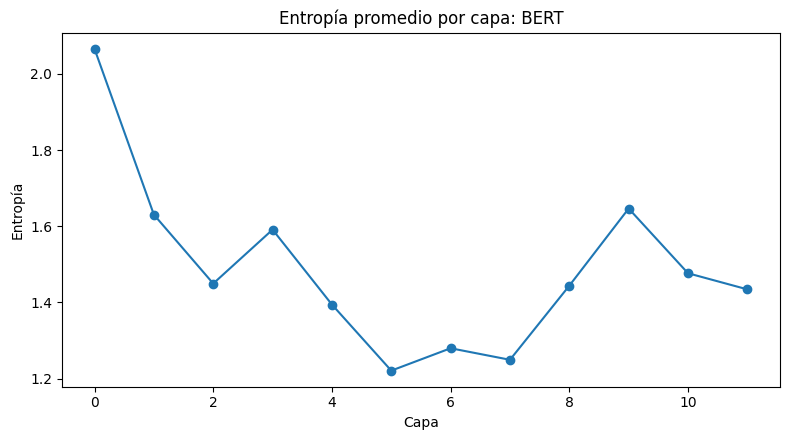

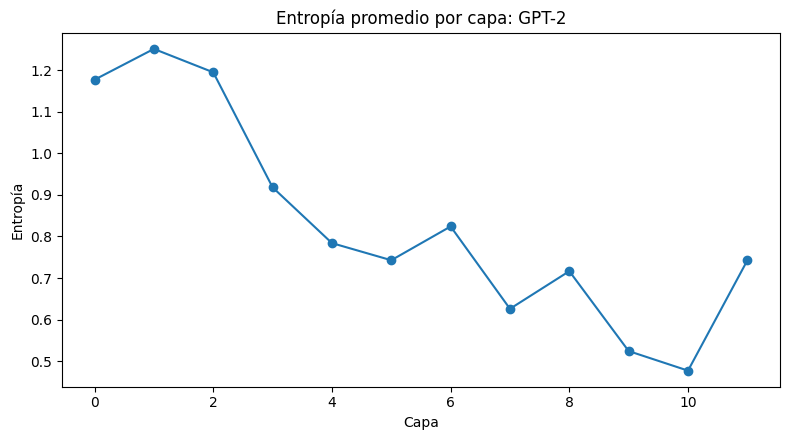

,layer,bert,gpt2
0,0,2.065293,1.177279
1,1,1.630419,1.251420
2,2,1.449641,1.195114
3,3,1.591148,0.918241
4,4,1.394576,0.784008
5,5,1.221201,0.742764
6,6,1.279928,0.824075
7,7,1.249649,0.625830
8,8,1.444091,0.716475
9,9,1.646505,0.524114


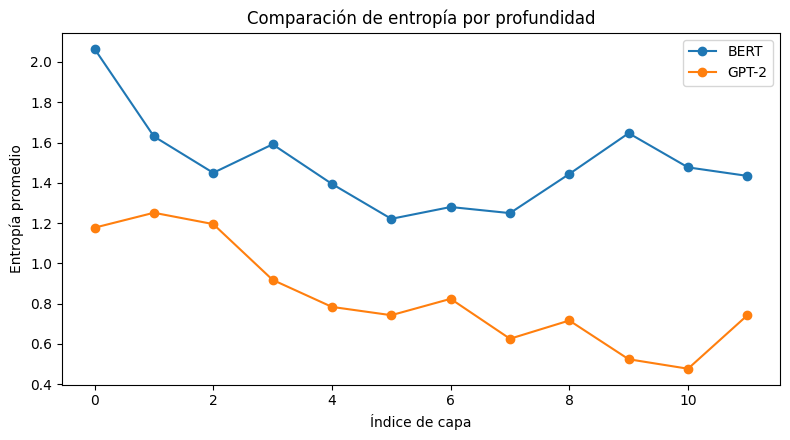

In [14]:
bert_entropy = mean_entropy_by_layer(bert_attentions)
gpt2_entropy = mean_entropy_by_layer(gpt2_attentions)
entropy_df = pd.DataFrame({'layer': np.arange(len(bert_entropy)), 'bert': bert_entropy, 'gpt2': gpt2_entropy})
entropy_df.to_csv(OUTPUTS / 'metrics' / 'entropy_by_layer.csv', index=False)
for name, values, folder in [('BERT', bert_entropy, 'bert'), ('GPT-2', gpt2_entropy, 'gpt2')]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(np.arange(len(values)), values, marker='o')
    ax.set(title=f'Entropía promedio por capa: {name}', xlabel='Capa', ylabel='Entropía')
    fig.tight_layout(); fig.savefig(OUTPUTS / folder / 'entropy_by_layer.png', dpi=150); plt.show(); plt.close(fig)
display(entropy_df)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(entropy_df['layer'], entropy_df['bert'], marker='o', label='BERT')
ax.plot(entropy_df['layer'], entropy_df['gpt2'], marker='o', label='GPT-2')
ax.set(title='Comparación de entropía por profundidad', xlabel='Índice de capa', ylabel='Entropía promedio'); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUTS / 'metrics' / 'entropy_comparison.png', dpi=150); plt.show(); plt.close(fig)